# Colab Intro

Sumę n wyrazów ciągu geometrycznego liczymy za pomocą następujących wzorów:
- Dla ilorazu $q \ne 1$:

$$
S_n=a_1 \times \frac{1-q^n}{1-q}
$$

- Dla ilorazu $q = 1$:

$$
S_n=a_1 \times n
$$

In [2]:
print(2+2)

4


In [3]:
import math
print(math.pi ** math.pi)

36.4621596072079


In [4]:
sum = 0
for i in range(100):
  sum += (i+1)*(i+1)
print(sum)

338350


In [5]:
with open("colab_wynik.txt", "w", encoding="utf-8") as f:
    f.write(str(sum))

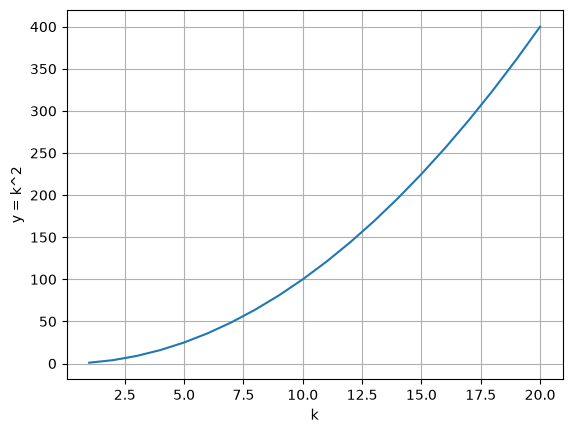

In [6]:
import matplotlib.pyplot as plt

k = []
y = []

for i in range(20):
  k.append(i+1)
  y.append((i+1)*(i+1))

plt.plot(k, y)
plt.xlabel("k")
plt.ylabel("y = k^2")
plt.grid()
plt.savefig("wykres.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
import base64
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp

g = 9.81  # Przyspieszenie ziemskie [m/s^2]
L = 1.0  # Długość wahadła [m]
theta0 = np.radians(45)  # Kąt początkowy
omega0 = 0.0  # Początkowa prędkość kątowa [rad/s]

fps = 30  # Liczba klatek na sekundę
t_max = 10  # Czas trwania animacji w sekundach
t_eval = np.linspace(0, t_max, int(fps * t_max))

def pendulum_equations(t, y):
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -(g / L) * np.sin(theta)
    return [dtheta_dt, domega_dt]

solution = solve_ivp(
    pendulum_equations,
    [0, t_max],
    [theta0, omega0],
    t_eval=t_eval,
    method="RK45",
)

theta_vals = solution.y[0]

x_vals = L * np.sin(theta_vals)
y_vals = -L * np.cos(theta_vals)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-L * 1.2, L * 1.2)
ax.set_ylim(-L * 1.2, L * 0.3)
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.6)
ax.set_title("Animacja Wahadła Prostego", fontsize=14)
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

(line,) = ax.plot([], [], lw=2, color="navy")
(bob,) = ax.plot([], [], "o", markersize=18, color="crimson")
ax.plot(0, 0, "k^", markersize=10)


def init():
    line.set_data([], [])
    bob.set_data([], [])
    return line, bob


def update(frame):
    x = x_vals[frame]
    y = y_vals[frame]
    line.set_data([0, x], [0, y])
    bob.set_data([x], [y])
    return line, bob


anim = FuncAnimation(
    fig,
    update,
    frames=len(t_eval),
    init_func=init,
    blit=True,
    interval=1000 / fps,
)
plt.close(fig)

output_filename = "video.mp4"

anim.save(
    output_filename,
    writer="ffmpeg",
    fps=fps,
    extra_args=["-vcodec", "libx264", "-pix_fmt", "yuv420p"],
)

with open(output_filename, "rb") as f:
    video_bytes = f.read()

video_b64 = base64.b64encode(video_bytes).decode("ascii")

HTML(f"""
<video width="500" height="500" controls autoplay loop>
  <source src="data:video/mp4;base64,{video_b64}" type="video/mp4">
  Twoja przeglądarka nie obsługuje tagu video.
</video>
""")

MovieWriter ffmpeg unavailable; using Pillow instead.


TypeError: AbstractMovieWriter.__init__() got an unexpected keyword argument 'extra_args'

In [8]:
import subprocess
from IPython.display import Image, display

input_video = "video.mp4"  # lub "video.mp4"
output_gif = "video.gif"

cmd = (
    f'ffmpeg -y -i {input_video} '
    f'-vf "fps=15,scale=500:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse" '
    f'{output_gif}'
)

subprocess.run(cmd, shell=True, check=True)

print("GIF wygenerowany pomyślnie z pełną jakością!")

display(Image(filename=output_gif))

CalledProcessError: Command 'ffmpeg -y -i video.mp4 -vf "fps=15,scale=500:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse" video.gif' returned non-zero exit status 1.

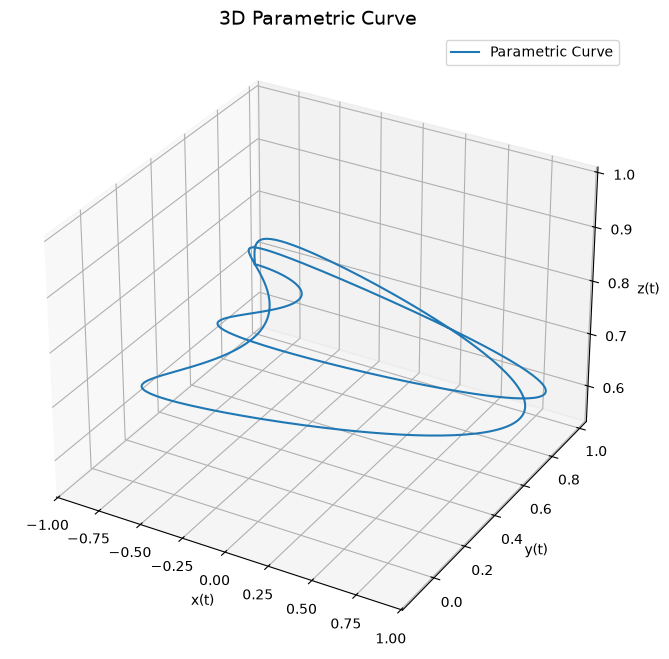

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

t = np.linspace(0, 2 * np.pi, 500)
x = np.sin(t) * np.cos(3*t)
y = np.sin(t) * np.sin(0.8*t)
z = np.cos(np.sin(t))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Parametric Curve")
ax.set_title("3D Parametric Curve", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()
fig.savefig("parametric_curve.png", dpi=300, bbox_inches="tight")
plt.show()

